# 00. 공통 설정

In [1]:
import re, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
import pmdarima as pm

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("Data")
END = "2024-12-01"        # 분석 데이터 마지막 달
SEASON = 12
HORIZON = 24              # 예측 기간: 2025.01 ~ 2026.12 (데이터 7~8년 대비 계절 주기 2바퀴)

In [2]:
def load_emissions(data_dir=DATA_DIR):
    # 엑셀 14개(연도×전기/가스)의 '총합' 행 1~12월 값을 월별 시계열로 정리
    rows = []
    for f in sorted(glob.glob(str(data_dir / "ghgEmissions_data*.xlsx"))):
        raw = pd.read_excel(f, header=None)
        title = str(raw.iloc[0, 0])
        year = int(re.search(r"(\d{4})년", title).group(1))
        kind = "전기" if "전기" in title else "가스"
        df = raw.iloc[2:].copy()
        df.columns = raw.iloc[1].tolist()
        total = df[df["자치구명"] == "총합"].iloc[0]
        for m in range(1, 13):
            rows.append((pd.Timestamp(year, m, 1), kind, float(total[f"{m}월"])))
    out = pd.DataFrame(rows, columns=["date", "kind", "tco2"]).pivot(index="date", columns="kind", values="tco2").sort_index()
    out.index.freq = "MS"
    return out

def stationarity_test(x, label):
    # ADF(H0: 비정상)와 KPSS(H0: 정상)를 함께 출력
    x = x.dropna()
    adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(x, regression="c", nlags="auto")[:2]
    adf_res = "귀무가설 기각 O → 정상" if adf_p < 0.05 else "귀무가설 기각 X → 비정상"
    kpss_res = "귀무가설 기각 O → 비정상" if kpss_p < 0.05 else "귀무가설 기각 X → 정상"
    print(f"[{label}]")
    print(f"  ADF  검정값 {adf_stat:8.4f} | p-value {adf_p:.4f} → {adf_res}   (H0: 정상성을 만족하지 못한다)")
    print(f"  KPSS 검정값 {kpss_stat:8.3f} | p-value {kpss_p:.4f} → {kpss_res}   (H0: 정상성을 만족한다)")
    if kpss_p >= 0.1:
        print("  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함")

def show_series(x, title, ylabel="", lags=24):
    # 시계열 그래프 + ACF + PACF를 한 줄로 그림
    x = x.dropna()
    lags = min(lags, len(x) // 2 - 1)
    fig = plt.figure(figsize=(14, 3.6))
    ax0 = fig.add_subplot(1, 3, 1); ax0.plot(x.index, x.values); ax0.set_title(title); ax0.set_ylabel(ylabel); ax0.grid(alpha=.3)
    plot_acf(x, lags=lags, ax=fig.add_subplot(1, 3, 2), title=f"ACF - {title}")
    plot_pacf(x, lags=lags, ax=fig.add_subplot(1, 3, 3), title=f"PACF - {title}", method="ywm")
    plt.tight_layout(); plt.show()

def residual_check(model, label):
    # 잔차 그래프·ACF, 포트만토(Ljung-Box) 검정, Jarque-Bera 검정
    r = model.resid.iloc[SEASON + 1:]          # 차분으로 영향을 받는 앞 13개 잔차 제외
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
    axes[0].plot(r.index, r.values); axes[0].axhline(0, color="k", lw=.8); axes[0].set_title(f"{label} 잔차"); axes[0].grid(alpha=.3)
    plot_acf(r, lags=24, ax=axes[1], title="잔차 ACF")
    plot_pacf(r, lags=24, ax=axes[2], title="잔차 PACF", method="ywm")
    plt.tight_layout(); plt.show()
    lb = acorr_ljungbox(r, lags=24, return_df=True)
    print(f"포트만토(Ljung-Box) 검정: lag 1~24 중 p-value가 0.05 미만인 시차 {int((lb['lb_pvalue'] < 0.05).sum())}개, "
          f"최솟값 {lb['lb_pvalue'].min():.3f}")
    print(f"Jarque-Bera p-value: {jarque_bera(r)[1]:.3f}  (H0: 잔차가 정규분포를 따른다)")
    return lb.loc[[1, 6, 12, 18, 24]].round(4)

def forecast(model, h=HORIZON, log=False):
    f = model.get_forecast(h)
    mean, ci = f.predicted_mean, f.conf_int(alpha=0.05)
    if log:
        mean, ci = np.exp(mean), np.exp(ci)
    return pd.DataFrame({"예측": mean, "하한": ci.iloc[:, 0], "상한": ci.iloc[:, 1]})

def plot_forecast(y, fc, title, ylabel, scale=1e4):
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(y.index, y / scale, color="k", label="관측값")
    ax.plot(fc.index, fc["예측"] / scale, "--", color="tab:red", label="예측값")
    ax.fill_between(fc.index, fc["하한"] / scale, fc["상한"] / scale, alpha=.25, color="orange", label="95% 신뢰구간")
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()

def yearly(s, scale=1e4):
    return (s.groupby(s.index.year).sum() / scale).round(1)

In [3]:
emis = load_emissions()[:END]
bike_df = pd.read_csv(DATA_DIR / "bike_monthly.csv", parse_dates=["date"]).set_index("date").sort_index()[:END]
bike_df.index.freq = "MS"
elec, gas, bike = emis["전기"], emis["가스"], bike_df["trips"]
for k, s in {"전기": elec, "가스": gas, "따릉이": bike}.items():
    print(f"{k:4s} {s.index.min():%Y-%m} ~ {s.index.max():%Y-%m}  {len(s)}개월  결측 {int(s.isna().sum())}")

전기   2018-01 ~ 2024-12  84개월  결측 0
가스   2018-01 ~ 2024-12  84개월  결측 0
따릉이  2017-01 ~ 2024-12  96개월  결측 0


# 02. 전기 사용량에 따른 온실가스 배출량

## 2-1. 원계열

연도별 배출량(만 tCO₂): {2018: 1961.4, 2019: 1944.8, 2020: 1873.6, 2021: 2046.9, 2022: 2112.3, 2023: 2129.0, 2024: 2079.4}


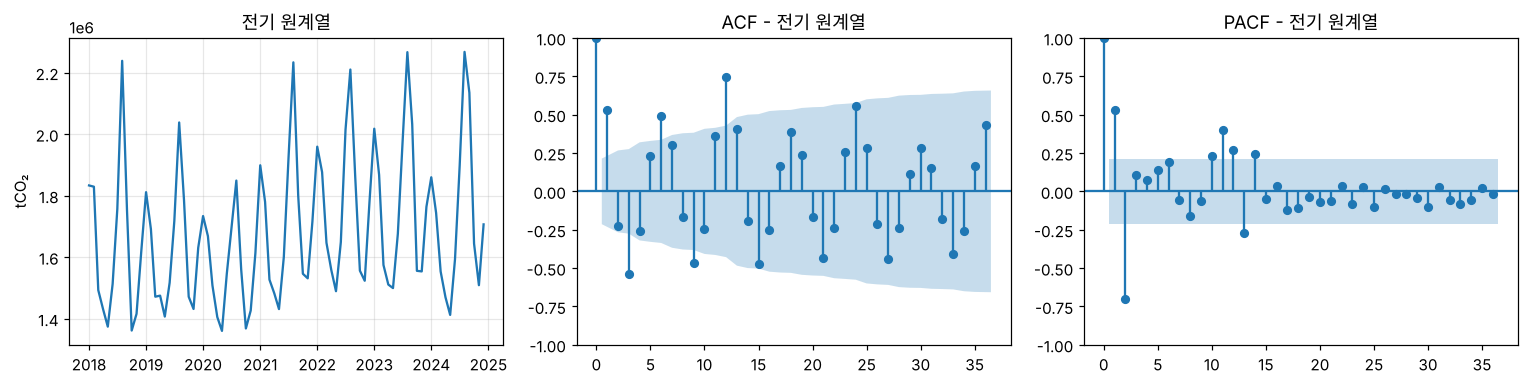

[전기 원계열]
  ADF  검정값  -0.9452 | p-value 0.7727 → 귀무가설 기각 X → 비정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.596 | p-value 0.0230 → 귀무가설 기각 O → 비정상   (H0: 정상성을 만족한다)


In [4]:
print("연도별 배출량(만 tCO₂):", yearly(elec).to_dict())
show_series(elec, "전기 원계열", "tCO₂", lags=36)
stationarity_test(elec, "전기 원계열")

## 2-2. 1차 차분

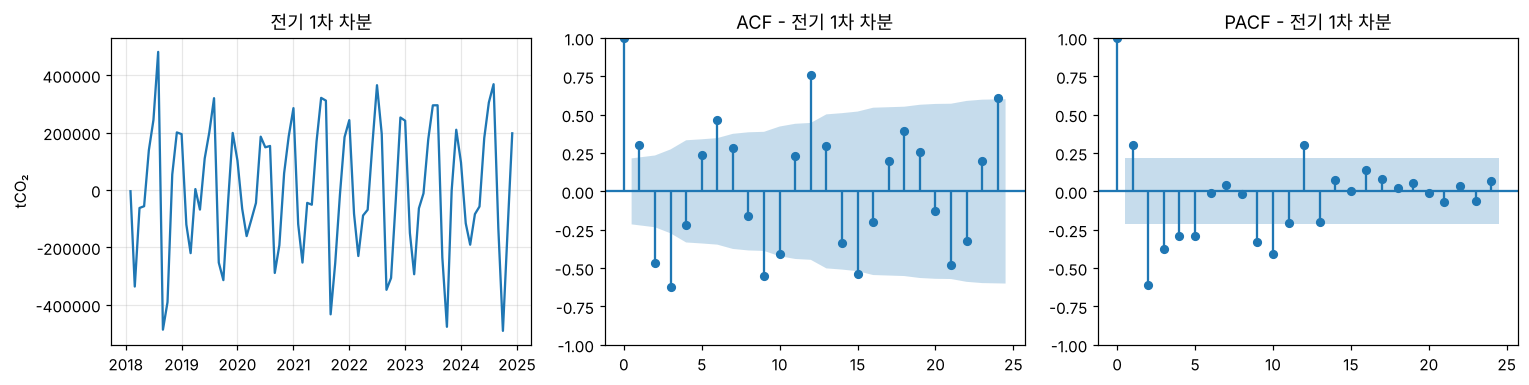

[전기 1차 차분]
  ADF  검정값  -3.5748 | p-value 0.0063 → 귀무가설 기각 O → 정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.050 | p-value 0.1000 → 귀무가설 기각 X → 정상   (H0: 정상성을 만족한다)
  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함


In [5]:
elec_d1 = elec.diff()
show_series(elec_d1, "전기 1차 차분", "tCO₂")
stationarity_test(elec_d1, "전기 1차 차분")

## 2-3. 1차 + 12개월 계절 차분

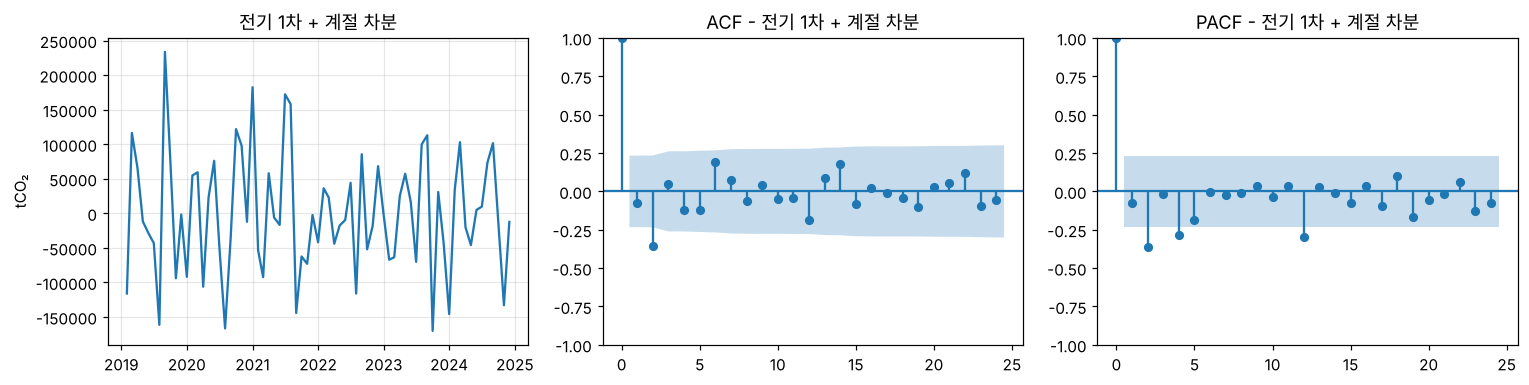

[전기 1차 + 계절 차분]
  ADF  검정값  -5.8548 | p-value 0.0000 → 귀무가설 기각 O → 정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.191 | p-value 0.1000 → 귀무가설 기각 X → 정상   (H0: 정상성을 만족한다)
  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함


In [6]:
elec_d = elec.diff().diff(SEASON)
show_series(elec_d, "전기 1차 + 계절 차분", "tCO₂")
stationarity_test(elec_d, "전기 1차 + 계절 차분")

## 2-4. 모델 적합: SARIMA(0,1,0)(0,1,2)₁₂

원 발표에서 auto_arima(AIC 기준)로 선택한 차수를 적합하고, 원 발표 결과표와 비교합니다.

In [7]:
elec_model = SARIMAX(elec, order=(0, 1, 0), seasonal_order=(0, 1, 2, SEASON)).fit(disp=False)
print(elec_model.summary().tables[1])
print(pd.DataFrame({"원 발표": {"ma.S.L12": -0.2104, "ma.S.L24": -0.1672, "AIC": 1799.725},
                    "재현": {"ma.S.L12": round(elec_model.params["ma.S.L12"], 4), "ma.S.L24": round(elec_model.params["ma.S.L24"], 4),
                            "AIC": round(elec_model.aic, 3)}}))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12      -0.2092      0.094     -2.233      0.026      -0.393      -0.026
ma.S.L24      -0.1654      0.067     -2.485      0.013      -0.296      -0.035
sigma2       7.25e+09    2.4e-13   3.02e+22      0.000    7.25e+09    7.25e+09
               원 발표         재현
ma.S.L12    -0.2104    -0.2092
ma.S.L24    -0.1672    -0.1654
AIC       1799.7250  1802.3200


## 2-5. 잔차 진단

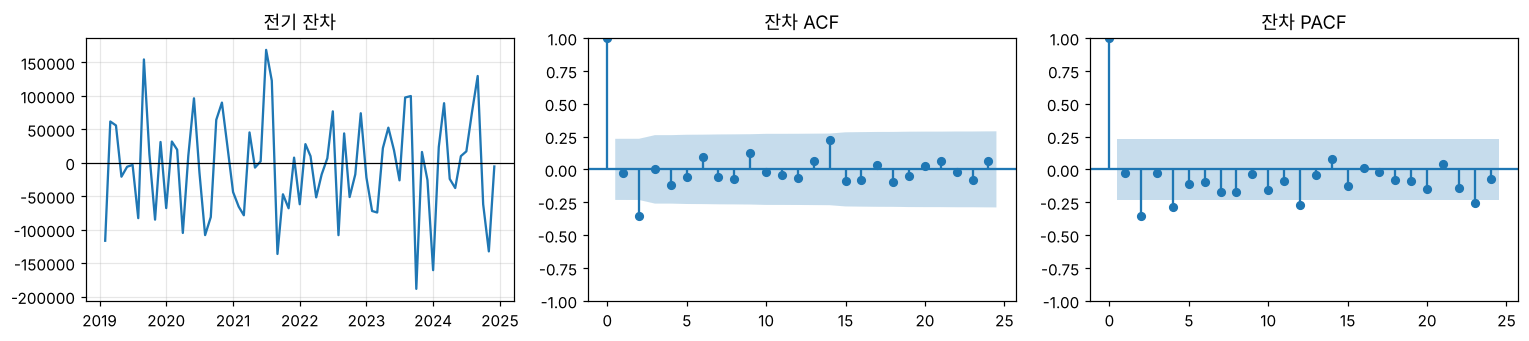

포트만토(Ljung-Box) 검정: lag 1~24 중 p-value가 0.05 미만인 시차 3개, 최솟값 0.009
Jarque-Bera p-value: 0.938  (H0: 잔차가 정규분포를 따른다)


,lb_stat,lb_pvalue
1,0.0664,0.7967
6,11.5736,0.0722
12,14.0362,0.2984
18,21.1895,0.2700
24,23.1997,0.5080


In [8]:
residual_check(elec_model, "전기")

## 2-6. 2025~2026년 예측

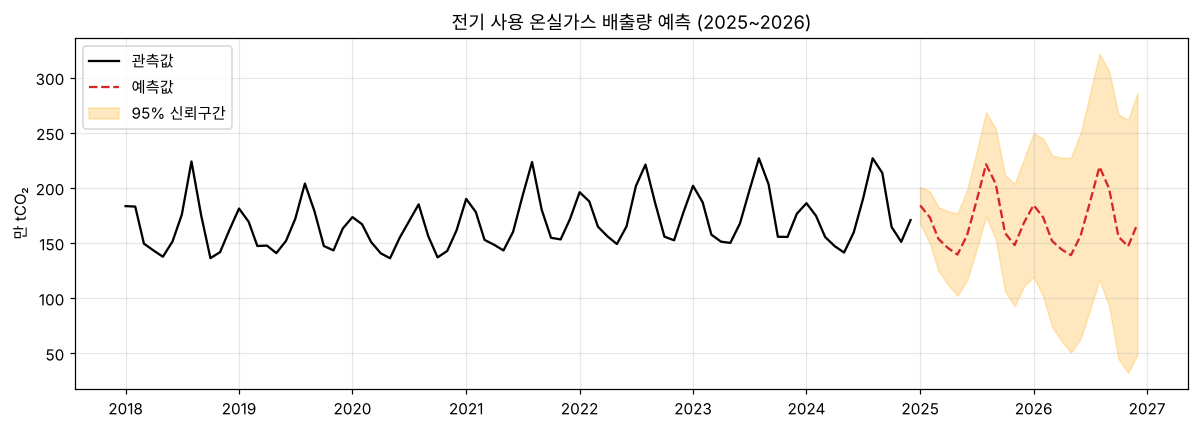

실측(만 tCO₂): {2022: 2112.3, 2023: 2129.0, 2024: 2079.4}
예측(만 tCO₂): {2025: 2039.9, 2026: 2022.8}


In [9]:
elec_fc = forecast(elec_model)
plot_forecast(elec, elec_fc, "전기 사용 온실가스 배출량 예측 (2025~2026)", "만 tCO₂")
print("실측(만 tCO₂):", yearly(elec).loc[2022:].to_dict())
print("예측(만 tCO₂):", yearly(elec_fc["예측"]).to_dict())

# 03. 가스 사용량에 따른 온실가스 배출량

## 3-1. 원계열

연도별 배출량(만 tCO₂): {2018: 946.0, 2019: 881.8, 2020: 838.0, 2021: 880.0, 2022: 913.9, 2023: 842.0, 2024: 824.3}


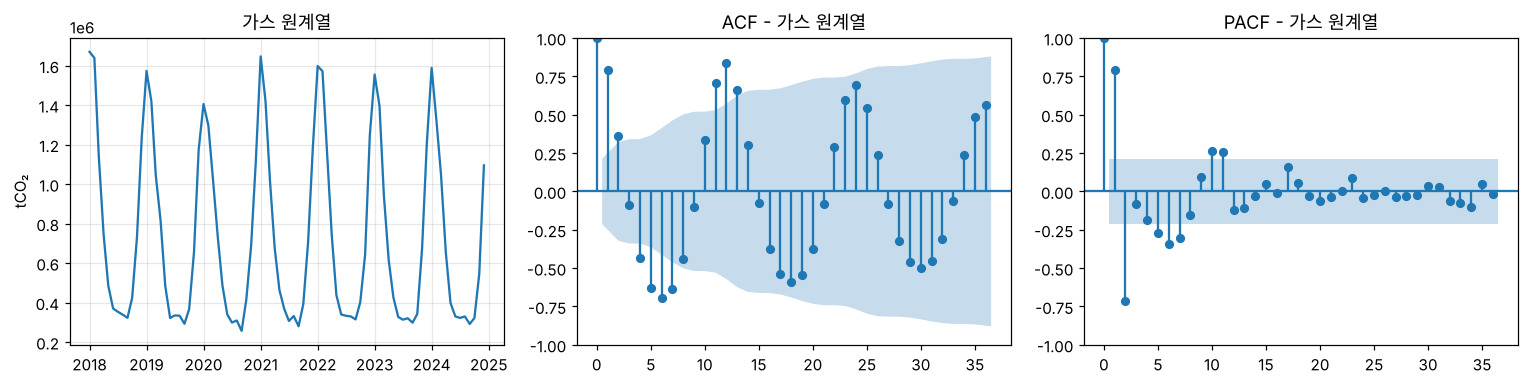

[가스 원계열]
  ADF  검정값  -1.7938 | p-value 0.3835 → 귀무가설 기각 X → 비정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.057 | p-value 0.1000 → 귀무가설 기각 X → 정상   (H0: 정상성을 만족한다)
  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함


In [10]:
print("연도별 배출량(만 tCO₂):", yearly(gas).to_dict())
show_series(gas, "가스 원계열", "tCO₂", lags=36)
stationarity_test(gas, "가스 원계열")

## 3-2. 로그 변환이 필요한 이유

원 발표 모델 SARIMA(0,1,0)(2,1,0)₁₂를 원 단위 그대로 적합하면 결과표는 재현되지만, 마지막 해의 감소폭을 계속 이어 가 예측이 지나치게 가파르게 줄어듭니다. 예측 2년 안에서도 연 10% 이상 줄고(과거 연평균 약 -2.3%), 원 발표처럼 4년까지 늘리면 **2028년 여름 예측값이 음수**가 됩니다. 배출량은 음수가 될 수 없으므로 로그 변환 후 분석합니다. 로그 예측을 `exp`로 되돌리면 항상 양수입니다.

In [11]:
gas_raw_model = SARIMAX(gas, order=(0, 1, 0), seasonal_order=(2, 1, 0, SEASON)).fit(disp=False)
print(f"원 발표 모델 재현: ar.S.L12 {gas_raw_model.params['ar.S.L12']:.4f} (원 발표 -0.2394), "
      f"ar.S.L24 {gas_raw_model.params['ar.S.L24']:.4f} (원 발표 -0.2226), AIC {gas_raw_model.aic:.3f} (원 발표 1785.677)")
raw_fc = gas_raw_model.get_forecast(48).predicted_mean      # 원 발표의 4년 예측으로 확인
print("원 단위 모델 연간 예측, 4년(만 tCO₂):", yearly(raw_fc).to_dict())
print("원 단위 모델 연도별 월 최솟값(만 tCO₂):", (raw_fc.groupby(raw_fc.index.year).min() / 1e4).round(1).to_dict())

원 발표 모델 재현: ar.S.L12 -0.2394 (원 발표 -0.2394), ar.S.L24 -0.2226 (원 발표 -0.2226), AIC 1785.677 (원 발표 1785.677)
원 단위 모델 연간 예측, 4년(만 tCO₂): {2025: 719.4, 2026: 623.4, 2027: 544.6, 2028: 459.8}
원 단위 모델 연도별 월 최솟값(만 tCO₂): {2025: 19.3, 2026: 11.4, 2027: 5.1, 2028: -2.1}


## 3-3. 로그 변환

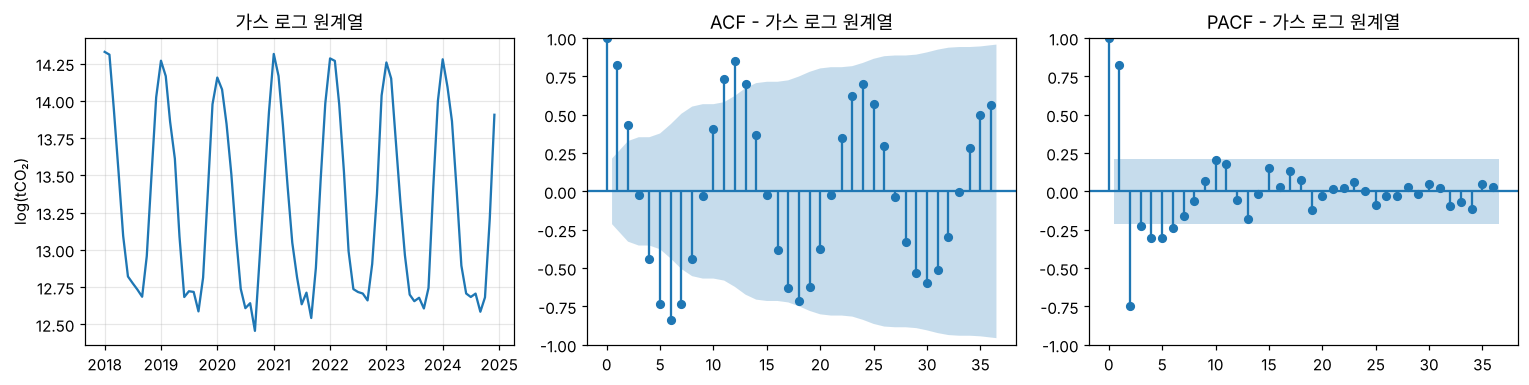

[가스 로그 원계열]
  ADF  검정값  -1.6122 | p-value 0.4768 → 귀무가설 기각 X → 비정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.055 | p-value 0.1000 → 귀무가설 기각 X → 정상   (H0: 정상성을 만족한다)
  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함


In [12]:
gas_log = np.log(gas)
show_series(gas_log, "가스 로그 원계열", "log(tCO₂)", lags=36)
stationarity_test(gas_log, "가스 로그 원계열")

## 3-4. 로그 + 1차 차분

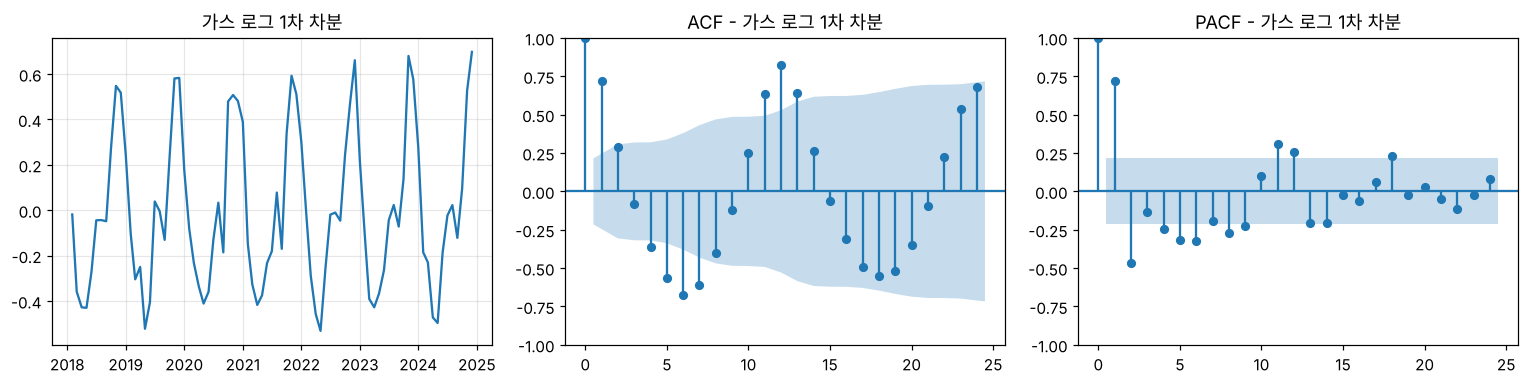

[가스 로그 1차 차분]
  ADF  검정값 -12.7296 | p-value 0.0000 → 귀무가설 기각 O → 정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.046 | p-value 0.1000 → 귀무가설 기각 X → 정상   (H0: 정상성을 만족한다)
  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함


In [13]:
gas_d1 = gas_log.diff()
show_series(gas_d1, "가스 로그 1차 차분")
stationarity_test(gas_d1, "가스 로그 1차 차분")

## 3-5. 로그 + 1차 + 12개월 계절 차분

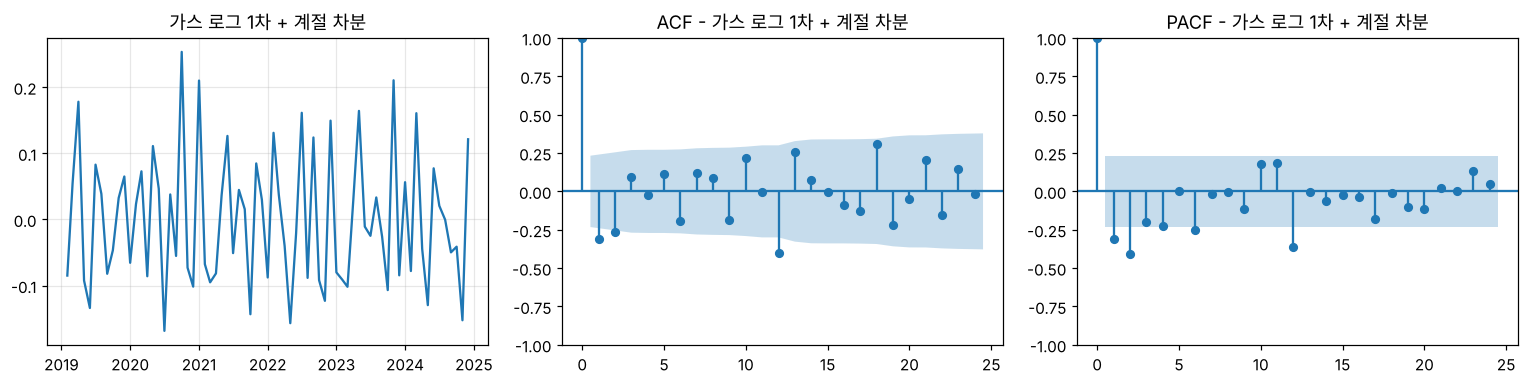

[가스 로그 1차 + 계절 차분]
  ADF  검정값  -2.7416 | p-value 0.0671 → 귀무가설 기각 X → 비정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.224 | p-value 0.1000 → 귀무가설 기각 X → 정상   (H0: 정상성을 만족한다)
  ※ KPSS p-value 0.1은 검정표 상한으로, 실제로는 0.1 이상을 뜻함


In [14]:
gas_d = gas_log.diff().diff(SEASON)
show_series(gas_d, "가스 로그 1차 + 계절 차분")
stationarity_test(gas_d, "가스 로그 1차 + 계절 차분")

## 3-6. 모델 선택: auto_arima (로그 데이터)

로그 변환으로 데이터가 바뀌었으므로, 원 발표와 같은 방법(차분 d=1, D=1 고정, AIC 기준 auto_arima)으로 차수를 다시 선택합니다.

In [15]:
auto_gas = pm.auto_arima(gas_log, seasonal=True, m=SEASON, d=1, D=1, stepwise=True,
                         information_criterion="aic", suppress_warnings=True)
GAS_ORDER, GAS_SORDER = auto_gas.order, auto_gas.seasonal_order
print("auto_arima 선택 차수:", GAS_ORDER, GAS_SORDER)

gas_model = SARIMAX(gas_log, order=GAS_ORDER, seasonal_order=GAS_SORDER).fit(disp=False)
old = SARIMAX(gas_log, order=(0, 1, 0), seasonal_order=(2, 1, 0, SEASON)).fit(disp=False)
print(f"AIC 비교 (로그 데이터): 선택 차수 {gas_model.aic:.2f} vs 원 발표 차수 (0,1,0)(2,1,0) {old.aic:.2f}")
print(gas_model.summary().tables[1])

auto_arima 선택 차수: (0, 1, 2) (0, 1, 1, 12)


AIC 비교 (로그 데이터): 선택 차수 -161.86 vs 원 발표 차수 (0,1,0)(2,1,0) -136.21
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5492      0.122     -4.516      0.000      -0.788      -0.311
ma.L2         -0.2787      0.130     -2.142      0.032      -0.534      -0.024
ma.S.L12      -0.6996      0.181     -3.864      0.000      -1.054      -0.345
sigma2         0.0047      0.001      4.734      0.000       0.003       0.007


## 3-7. 잔차 진단

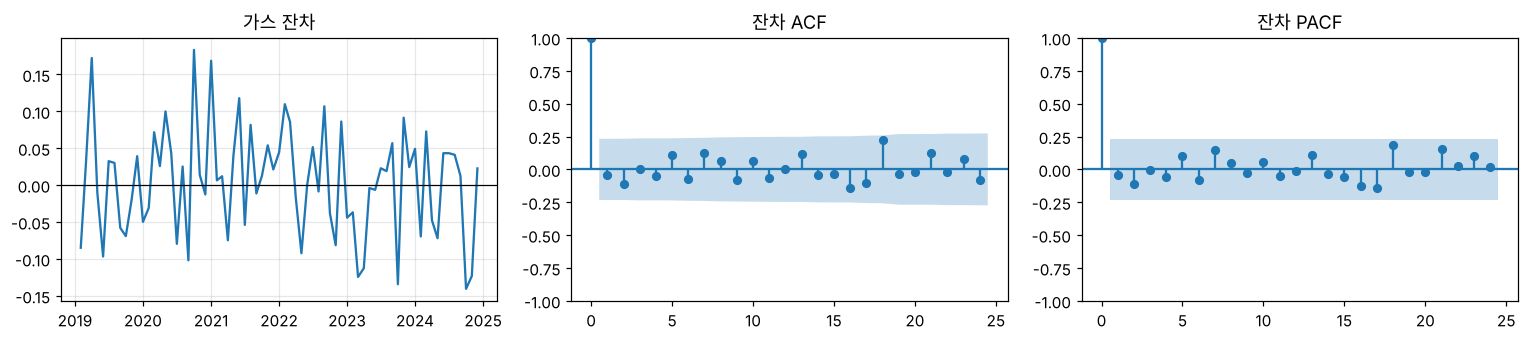

포트만토(Ljung-Box) 검정: lag 1~24 중 p-value가 0.05 미만인 시차 0개, 최솟값 0.586
Jarque-Bera p-value: 0.851  (H0: 잔차가 정규분포를 따른다)


,lb_stat,lb_pvalue
1,0.1161,0.7333
6,2.5687,0.8607
12,5.4925,0.9395
18,14.9167,0.6677
24,18.1779,0.7943


In [16]:
residual_check(gas_model, "가스")

## 3-8. 2025~2026년 예측

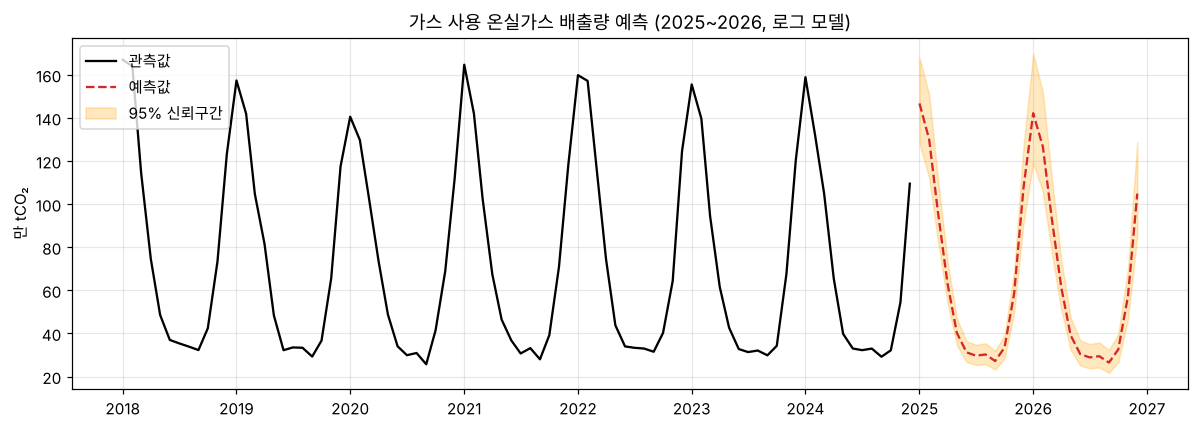

실측(만 tCO₂):

 {2022: 913.9, 2023: 842.0, 2024: 824.3}
예측(만 tCO₂): {2025: 794.9, 2026: 773.1}
예측 월 최솟값: 26.5만 tCO₂ (음수 없음)


In [17]:
gas_fc = forecast(gas_model, log=True)
plot_forecast(gas, gas_fc, "가스 사용 온실가스 배출량 예측 (2025~2026, 로그 모델)", "만 tCO₂")
print("실측(만 tCO₂):", yearly(gas).loc[2022:].to_dict())
print("예측(만 tCO₂):", yearly(gas_fc["예측"]).to_dict())
print(f"예측 월 최솟값: {gas_fc['예측'].min()/1e4:.1f}만 tCO₂ (음수 없음)")

# 04. 탄소 절감 방안: 따릉이

## 4-1. 원계열

연도별 이용 건수(만 건): {2017: 503.1, 2018: 1006.9, 2019: 1899.1, 2020: 2367.4, 2021: 3203.3, 2022: 4095.1, 2023: 4490.5, 2024: 4385.0}


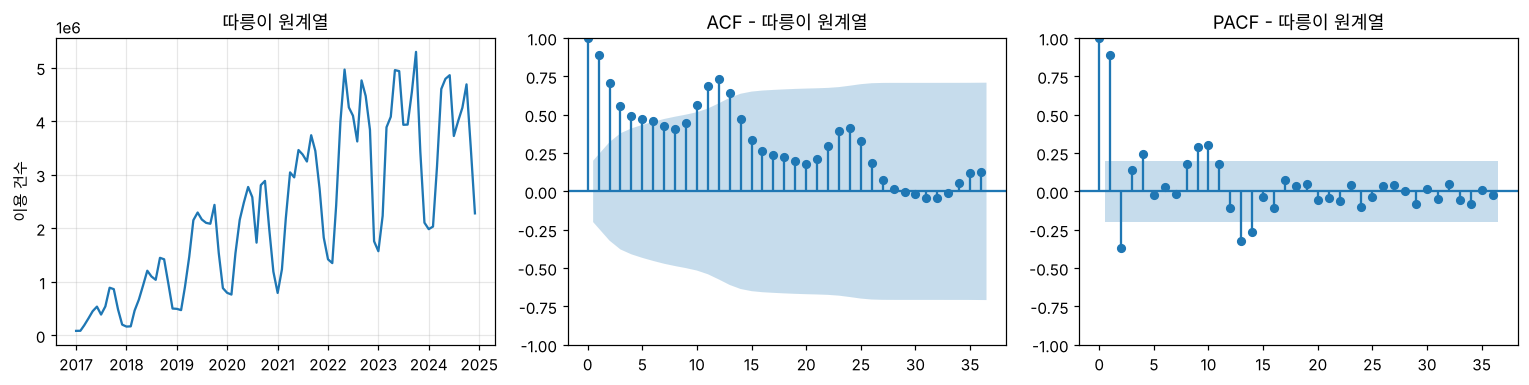

[따릉이 원계열]
  ADF  검정값  -1.9703 | p-value 0.2997 → 귀무가설 기각 X → 비정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    1.477 | p-value 0.0100 → 귀무가설 기각 O → 비정상   (H0: 정상성을 만족한다)


In [18]:
print("연도별 이용 건수(만 건):", yearly(bike).to_dict())
show_series(bike, "따릉이 원계열", "이용 건수", lags=36)
stationarity_test(bike, "따릉이 원계열")

## 4-2. 로그 변환

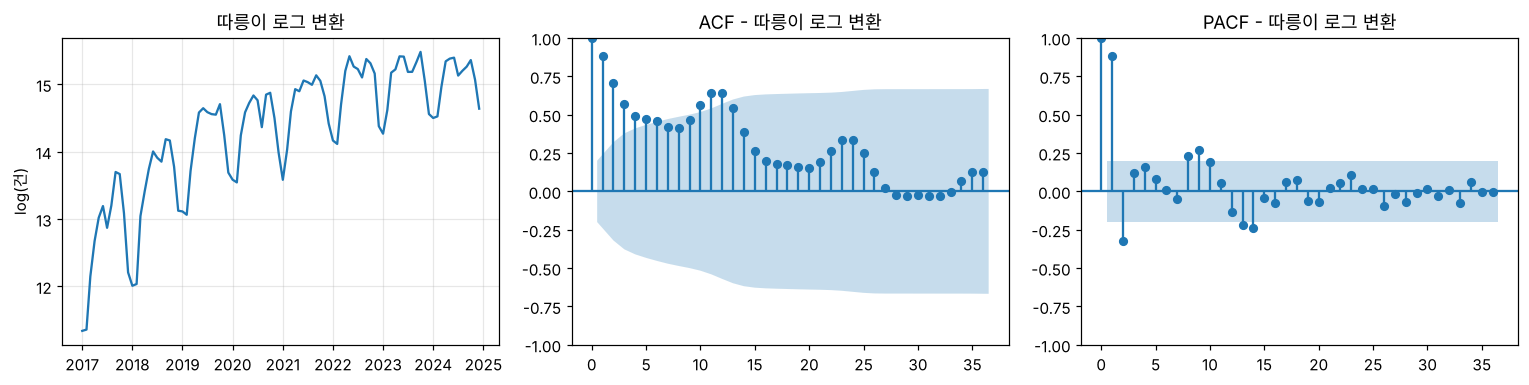

[따릉이 로그 변환]
  ADF  검정값  -7.9344 | p-value 0.0000 → 귀무가설 기각 O → 정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    1.418 | p-value 0.0100 → 귀무가설 기각 O → 비정상   (H0: 정상성을 만족한다)


In [19]:
bike_log = np.log(bike)
show_series(bike_log, "따릉이 로그 변환", "log(건)", lags=36)
stationarity_test(bike_log, "따릉이 로그 변환")

## 4-3. 로그 + 12개월 계절 차분

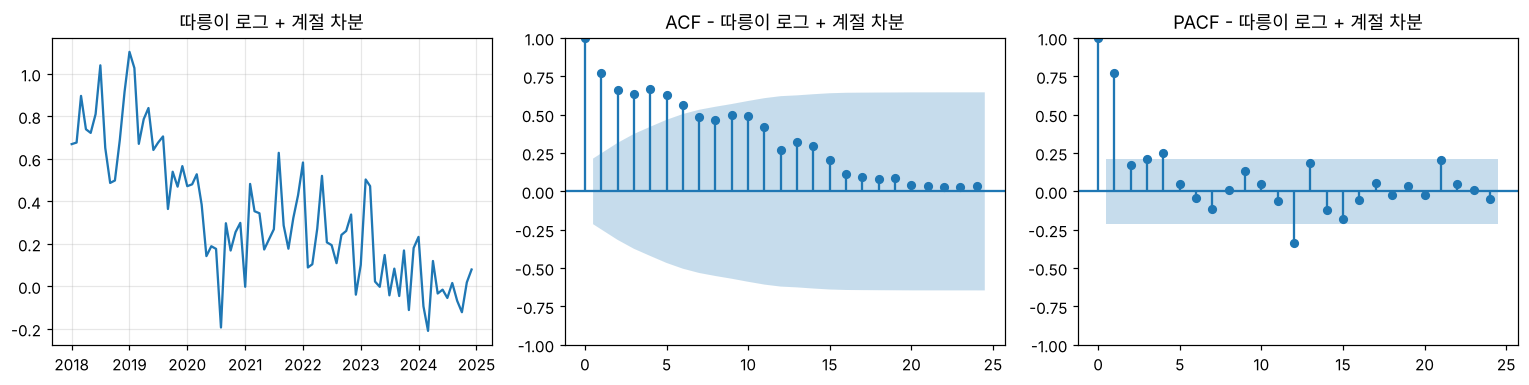

[따릉이 로그 + 계절 차분]
  ADF  검정값  -1.8770 | p-value 0.3430 → 귀무가설 기각 X → 비정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    1.221 | p-value 0.0100 → 귀무가설 기각 O → 비정상   (H0: 정상성을 만족한다)


In [20]:
bike_sd = bike_log.diff(SEASON)
show_series(bike_sd, "따릉이 로그 + 계절 차분")
stationarity_test(bike_sd, "따릉이 로그 + 계절 차분")

## 4-4. 로그 + 계절 차분 + 1차 차분

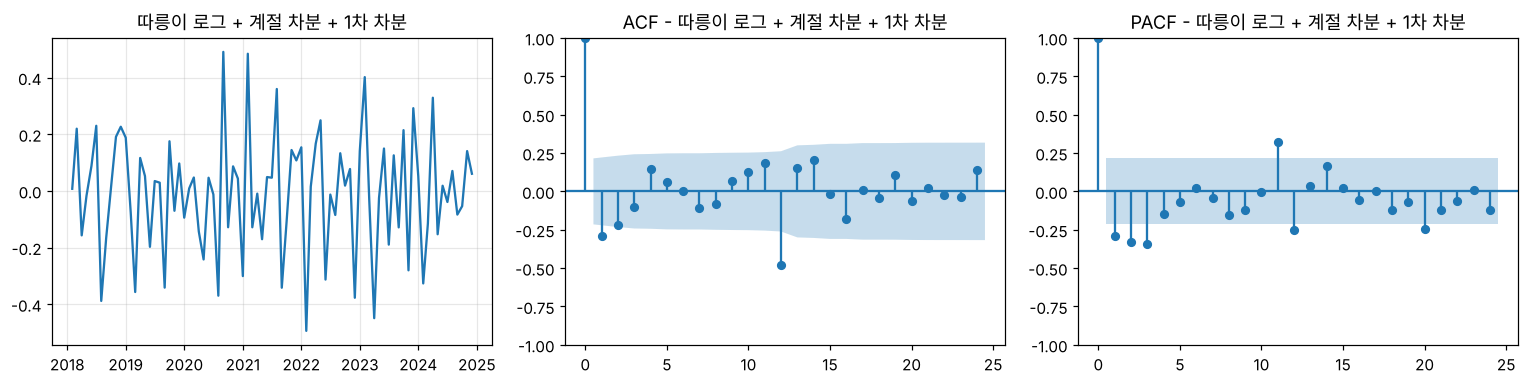

[따릉이 로그 + 계절 차분 + 1차 차분]
  ADF  검정값  -3.1120 | p-value 0.0257 → 귀무가설 기각 O → 정상   (H0: 정상성을 만족하지 못한다)
  KPSS 검정값    0.500 | p-value 0.0417 → 귀무가설 기각 O → 비정상   (H0: 정상성을 만족한다)


In [21]:
bike_d = bike_log.diff(SEASON).diff()
show_series(bike_d, "따릉이 로그 + 계절 차분 + 1차 차분")
stationarity_test(bike_d, "따릉이 로그 + 계절 차분 + 1차 차분")

## 4-5. 모델 적합: SARIMA(0,1,1)(1,1,0)₁₂

원 발표에서 포트만토 검정(p > 0.05)과 AIC 기준으로 선정한 모델입니다. 원 발표와 같이 정상성·가역성 제약 없이 적합합니다.

In [22]:
bike_model = SARIMAX(bike_log, order=(0, 1, 1), seasonal_order=(1, 1, 0, SEASON),
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(bike_model.summary().tables[1])
print(pd.DataFrame({"원 발표": {"ma.L1": -0.5015, "ar.S.L12": -0.4321, "AIC": -50.261},
                    "재현": {"ma.L1": round(bike_model.params["ma.L1"], 4), "ar.S.L12": round(bike_model.params["ar.S.L12"], 4),
                            "AIC": round(bike_model.aic, 3)}}))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5011      0.117     -4.265      0.000      -0.731      -0.271
ar.S.L12      -0.4392      0.105     -4.196      0.000      -0.644      -0.234
sigma2         0.0264      0.004      6.102      0.000       0.018       0.035
             원 발표       재현
ma.L1     -0.5015  -0.5011
ar.S.L12  -0.4321  -0.4392
AIC      -50.2610 -50.2280


## 4-6. 잔차 진단

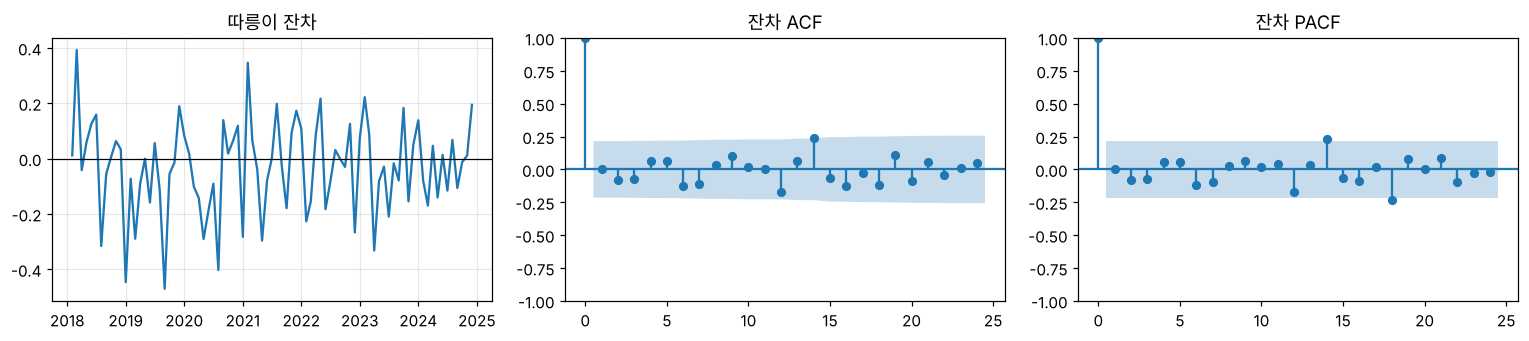

포트만토(Ljung-Box) 검정: lag 1~24 중 p-value가 0.05 미만인 시차 0개, 최솟값 0.388
Jarque-Bera p-value: 0.502  (H0: 잔차가 정규분포를 따른다)


,lb_stat,lb_pvalue
1,0.0001,0.9939
6,3.2665,0.7747
12,8.4684,0.7475
18,18.5695,0.4188
24,21.5031,0.6089


In [23]:
residual_check(bike_model, "따릉이")

## 4-7. 2025~2026년 이용 건수 예측

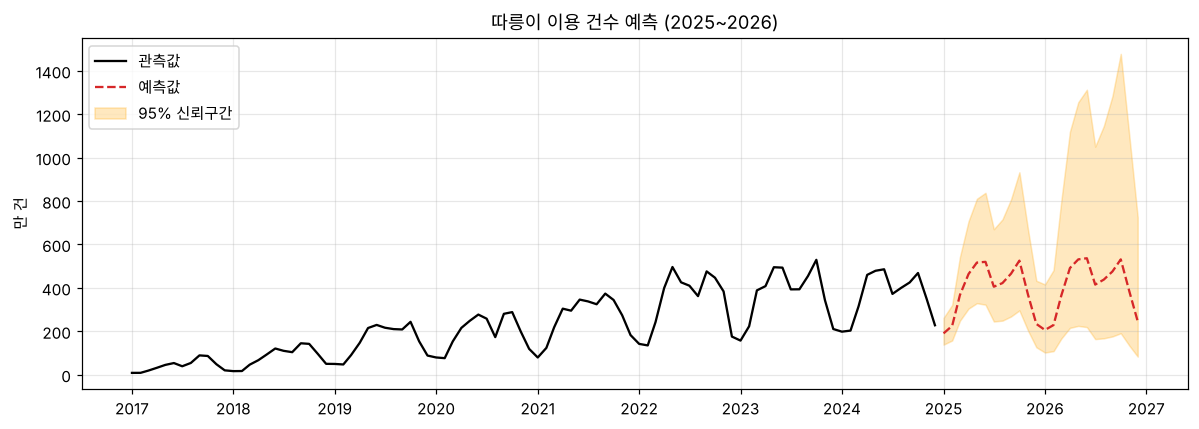

실측(만 건): {2022: 4095.1, 2023: 4490.5, 2024: 4385.0}
예측(만 건): {2025: 4705.6, 2026: 4849.3}


In [24]:
bike_fc = forecast(bike_model, log=True)
plot_forecast(bike, bike_fc, "따릉이 이용 건수 예측 (2025~2026)", "만 건")
print("실측(만 건):", yearly(bike).loc[2022:].to_dict())
print("예측(만 건):", yearly(bike_fc["예측"]).to_dict())

## 4-8. 따릉이 이용에 따른 탄소 절감량

**배출 감소 계수 (0.232 kg CO₂/km)**: 일반 승용차(2,000cc급, 휘발유) 시내 주행 연비 10km/L를 적용한 에너지관리공단 수송에너지 계산식

  CO₂(g/km) = (640 g/L ÷ 10 km/L − (0.866 + 0.429)) ÷ 0.273 ≈ 230 → 공식 계수 232 g/km(원본 데이터 `탄소량` 계산과 동일)를 사용

**최종식**: 월별 CO₂ 절감량(kg) = ŷₜ(예측 이용 건수) × 건당 평균 이동거리(km) × 0.232

**건당 평균 이동거리**: 2017~2024년 전체 이동거리 ÷ 전체 이용 건수. 원 발표는 월별 평균 거리를 다시 평균했는데, 이 방식은 이용이 적었던 초기 몇 년(건당 거리가 긴 시기)의 비중이 커져 평균이 길게 나오므로 전체 합 기준으로 바로잡았습니다.

In [25]:
EF_KG_PER_KM = (640 / 10 - (0.866 + 0.429)) / 0.273 / 1000
print(f"배출 감소 계수: {EF_KG_PER_KM*1000:.1f} g/km → 계산에는 0.232 kg/km 사용")
EF_KG_PER_KM = 0.232

# 원본 데이터의 '탄소량' 컬럼도 같은 계수로 계산되어 있는지 확인
chk = bike_df.groupby(bike_df.index.year)[["carbon_kg", "dist_km"]].sum()
display(pd.DataFrame({"원본 탄소량(tCO₂)": chk["carbon_kg"] / 1000,
                      "이동거리×0.232(tCO₂)": chk["dist_km"] * EF_KG_PER_KM / 1000}).round(0).T)

AVG_KM = bike_df["dist_km"].sum() / bike_df["trips"].sum()   # 2017~2024 전체 이동거리 ÷ 전체 이용 건수
print(f"건당 평균 이동거리(2017~2024 전체 평균): {AVG_KM:.4f} km")
print(f"참고: 원 발표 3.1634 km는 월별 평균 거리를 다시 평균한 값(재계산 {(bike_df['dist_km'] / bike_df['trips']).mean():.4f} km)")
yr = bike_df.groupby(bike_df.index.year)[["dist_km", "trips"]].sum()
print("연도별 건당 거리(km):", (yr["dist_km"] / yr["trips"]).round(2).to_dict())

배출 감소 계수: 229.7 g/km → 계산에는 0.232 kg/km 사용


date,2017,2018,2019,2020,2021,2022,2023,2024
원본 탄소량(tCO₂),4228.0,10611.0,22142.0,15674.0,20795.0,24407.0,25085.0,23894.0
이동거리×0.232(tCO₂),4228.0,10611.0,22140.0,15674.0,20796.0,24404.0,25154.0,23991.0


건당 평균 이동거리(2017~2024 전체 평균): 2.8866 km
참고: 원 발표 3.1634 km는 월별 평균 거리를 다시 평균한 값(재계산 3.1694 km)
연도별 건당 거리(km): {2017: 3.62, 2018: 4.54, 2019: 5.03, 2020: 2.85, 2021: 2.8, 2022: 2.57, 2023: 2.41, 2024: 2.36}


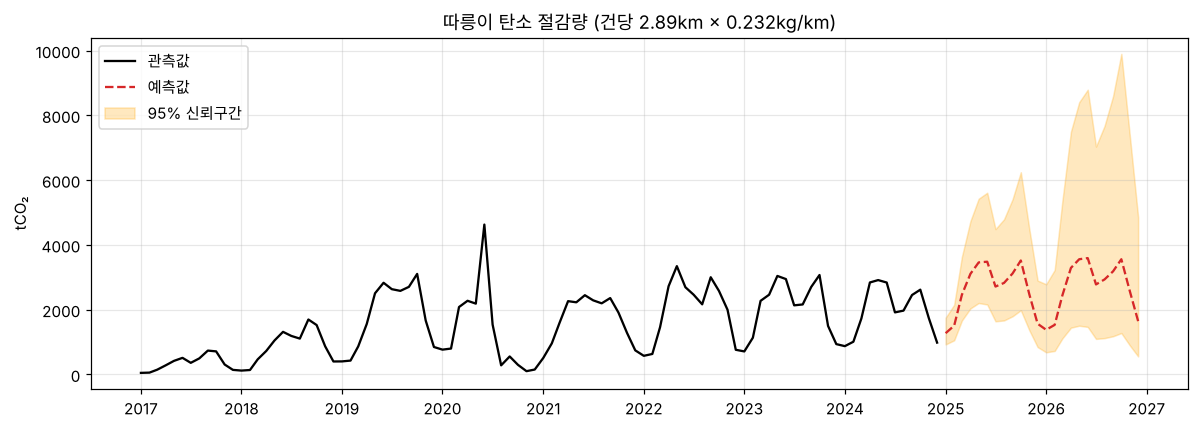

실측 절감량(tCO₂): {2022: 24407.0, 2023: 25085.0, 2024: 23894.4}
예측 절감량(tCO₂): {2025: 31512.0, 2026: 32475.0}
2017~2022 누적 실측 절감량: 97,858 tCO₂


In [26]:
red_fc = bike_fc * AVG_KM * EF_KG_PER_KM / 1000          # tCO₂ (예측·하한·상한)
hist_red = bike_df["carbon_kg"] / 1000
plot_forecast(hist_red, red_fc, f"따릉이 탄소 절감량 (건당 {AVG_KM:.2f}km × 0.232kg/km)", "tCO₂", scale=1)
print("실측 절감량(tCO₂):", yearly(hist_red, 1).loc[2022:].to_dict())
print("예측 절감량(tCO₂):", yearly(red_fc["예측"], 1).round(0).to_dict())
print(f"2017~2022 누적 실측 절감량: {hist_red['2017':'2022'].sum():,.0f} tCO₂")

# 06. 결론

In [27]:
summary = pd.DataFrame({
    "전기(만 tCO₂)": pd.concat([yearly(elec), yearly(elec_fc["예측"])]),
    "가스(만 tCO₂)": pd.concat([yearly(gas), yearly(gas_fc["예측"])]),
    "따릉이(만 건)": pd.concat([yearly(bike), yearly(bike_fc["예측"])]),
    "따릉이 절감(tCO₂)": pd.concat([yearly(hist_red, 1), yearly(red_fc["예측"], 1)]).round(0),
})
summary["전기+가스(만 tCO₂)"] = summary["전기(만 tCO₂)"] + summary["가스(만 tCO₂)"]
summary["절감/배출(%)"] = (summary["따릉이 절감(tCO₂)"] / (summary["전기+가스(만 tCO₂)"] * 1e4) * 100).round(3)
summary["구분"] = np.where(summary.index >= 2025, "예측", "실측")
display(summary.loc[2018:])

f = summary.loc[2025:2026]
print(f"2025~2026 누적: 전기+가스 배출 {f['전기+가스(만 tCO₂)'].sum():,.1f}만 tCO₂, "
      f"따릉이 절감 {f['따릉이 절감(tCO₂)'].sum():,.0f} tCO₂ ({f['따릉이 절감(tCO₂)'].sum()/(f['전기+가스(만 tCO₂)'].sum()*1e4)*100:.2f}%)")

,전기(만 tCO₂),가스(만 tCO₂),따릉이(만 건),따릉이 절감(tCO₂),전기+가스(만 tCO₂),절감/배출(%),구분
2018,1961.4,946.0,1006.9,10611.0,2907.4,0.036,실측
2019,1944.8,881.8,1899.1,22142.0,2826.6,0.078,실측
2020,1873.6,838.0,2367.4,15674.0,2711.6,0.058,실측
2021,2046.9,880.0,3203.3,20795.0,2926.9,0.071,실측
2022,2112.3,913.9,4095.1,24407.0,3026.2,0.081,실측
2023,2129.0,842.0,4490.5,25085.0,2971.0,0.084,실측
2024,2079.4,824.3,4385.0,23894.0,2903.7,0.082,실측
2025,2039.9,794.9,4705.6,31512.0,2834.8,0.111,예측
2026,2022.8,773.1,4849.3,32475.0,2795.9,0.116,예측


2025~2026 누적: 전기+가스 배출 5,630.7만 tCO₂, 따릉이 절감 63,987 tCO₂ (0.11%)
